# Notebook 4 — Comparaison des modèles : SVM vs Random Forest vs XGBoost

## 1. Chargement des bibliothèques et des données

Les trois modèles sont **ré-entraînés ici avec exactement les mêmes hyperparamètres retenus comme "modèle final" dans chacun des trois notebooks individuels**. Cela permet de les évaluer tous les trois dans les mêmes conditions, sur le même run, ce qui rend la comparaison plus rigoureuse qu'un simple copier-coller de chiffres provenant de notebooks exécutés séparément.


> **⚠️ Important : Version de scikit-learn**
>
> Ce notebook a été développé et testé avec **scikit-learn 1.7.2**, comme les trois notebooks de modélisation individuels (SVM, Random Forest, XGBoost).
>
> L'utilisation d'une version différente peut entraîner des variations dans les résultats (métriques, comportement de certains algorithmes ou fonctions, compatibilité de certaines API, etc.). Pour garantir la reproductibilité des expériences et obtenir les mêmes résultats que ceux présentés dans les notebooks individuels, il est recommandé d'utiliser **scikit-learn 1.7.2**.

In [2]:
import pickle
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    ConfusionMatrixDisplay
)
from sklearn.preprocessing import label_binarize

plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")
RANDOM_STATE = 42

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


In [3]:
# --- Chargement des données préparées par le Notebook 1 (ETL) ---
with open("prepared_fetal_data.pkl", "rb") as f:
    donnees = pickle.load(f)

X_train = donnees["X_train"]
X_test  = donnees["X_test"]
y_train = donnees["y_train"]
y_test  = donnees["y_test"]
class_names = donnees["class_names"]   # ["Normal", "Suspect", "Pathologique"]

print(f"X_train : {X_train.shape}   |   X_test : {X_test.shape}")
print(f"y_train : {y_train.shape}   |   y_test : {y_test.shape}")
print("\nRépartition des classes dans y_test (%) :")
print((y_test.value_counts(normalize=True) * 100).round(2))

X_train : (1690, 21)   |   X_test : (423, 21)
y_train : (1690,)   |   y_test : (423,)

Répartition des classes dans y_test (%) :
fetal_health
0    78.01
1    13.71
2     8.27
Name: proportion, dtype: float64


## 2. Les trois modèles retenus

Chaque notebook individuel a testé une version "baseline" et une version "optimisée" (recherche d'hyperparamètres), puis a choisi la version la plus adaptée comme modèle final. Le tableau ci-dessous résume ce choix et sa justification.

| Modèle | Version retenue | Pourquoi |
|:--|:--|:--|
| **SVM** | Optimisé (`GridSearchCV`) | Un seul modèle a été construit, directement optimisé par validation croisée sur le F1-score macro. |
| **Random Forest** | Optimisé (`RandomizedSearchCV` + `GridSearchCV`) | La version optimisée améliore le recall macro (0.8745 → 0.8944) et surtout le recall de la classe Suspect (68.97 % → 75.86 %) par rapport au baseline, ce qui est jugé prioritaire en contexte médical. Le recall de la classe Pathologique reste, lui, inchangé (94.29 % dans les deux cas) : ce n'est donc pas ce recall qui motive le choix de l'optimisé. L'accuracy globale augmente même très légèrement (94.56 % → 94.80 %) ; c'est la precision macro qui baisse un peu (0.9575 → 0.9271), traduisant un léger surcroît de faux positifs, jugé acceptable au vu du gain de recall. |
| **XGBoost** | Baseline (hyperparamètres par défaut + équilibrage) | La recherche d'hyperparamètres (`GridSearchCV`) a produit un modèle légèrement moins performant que le baseline sur toutes les métriques. Le baseline est donc conservé, un cas classique où le réglage "raisonnable" choisi manuellement généralise mieux que la combinaison retenue par la validation croisée. |

Nous reconstruisons donc ci-dessous ces trois modèles avec leurs hyperparamètres respectifs.


In [4]:
# ============================================================
#  MODÈLE 1 — SVM (noyau RBF, hyperparamètres du Notebook SVM)
# ============================================================
t0 = time.time()
modele_svm = SVC(
    kernel="rbf",
    C=50,
    gamma=0.1,
    class_weight="balanced",
    probability=True,
    random_state=RANDOM_STATE,
)
modele_svm.fit(X_train, y_train)
temps_svm = time.time() - t0

y_pred_svm  = modele_svm.predict(X_test)
y_proba_svm = modele_svm.predict_proba(X_test)

print(f"SVM entraîné en {temps_svm:.3f} secondes.")
print(f"Hyperparamètres : C=50, gamma=0.1, kernel='rbf', class_weight='balanced'")

SVM entraîné en 0.969 secondes.
Hyperparamètres : C=50, gamma=0.1, kernel='rbf', class_weight='balanced'


In [5]:
# ============================================================
#  MODÈLE 2 — Random Forest optimisé (hyperparamètres du Notebook RF)
# ============================================================
t0 = time.time()
modele_rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=30,
    max_features="sqrt",
    min_samples_leaf=2,
    min_samples_split=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
)
modele_rf.fit(X_train, y_train)
temps_rf = time.time() - t0

y_pred_rf  = modele_rf.predict(X_test)
y_proba_rf = modele_rf.predict_proba(X_test)

print(f"Random Forest entraîné en {temps_rf:.3f} secondes.")
print(f"Hyperparamètres : n_estimators=500, max_depth=30, max_features='sqrt', "
      f"min_samples_leaf=2, min_samples_split=2, class_weight='balanced'")

Random Forest entraîné en 2.951 secondes.
Hyperparamètres : n_estimators=500, max_depth=30, max_features='sqrt', min_samples_leaf=2, min_samples_split=2, class_weight='balanced'


In [6]:
# ============================================================
#  MODÈLE 3 — XGBoost baseline (hyperparamètres du Notebook XGBoost)
# ============================================================
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

t0 = time.time()
modele_xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    verbosity=0,
)
modele_xgb.fit(X_train, y_train, sample_weight=sample_weights)
temps_xgb = time.time() - t0

y_pred_xgb  = modele_xgb.predict(X_test)
y_proba_xgb = modele_xgb.predict_proba(X_test)

print(f"XGBoost entraîné en {temps_xgb:.3f} secondes.")
print(f"Hyperparamètres : n_estimators=200, max_depth=5, learning_rate=0.1, "
      f"subsample=0.8, colsample_bytree=0.8, pondération via sample_weight")

XGBoost entraîné en 0.713 secondes.
Hyperparamètres : n_estimators=200, max_depth=5, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, pondération via sample_weight


## 3. Tableau comparatif des métriques globales

Nous calculons maintenant, pour chaque modèle, les métriques globales sur le jeu de test : accuracy, precision macro, recall macro, F1-score macro, F1-score pondéré, et l'AUC macro (moyenne des AUC One-vs-Rest des trois classes).


In [7]:
def calculer_metriques(y_true, y_pred, y_proba, nom_modele):
    y_true_bin = label_binarize(y_true, classes=[0, 1, 2])
    auc_par_classe = [roc_auc_score(y_true_bin[:, i], y_proba[:, i]) for i in range(3)]
    return {
        "Modèle": nom_modele,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (macro)": precision_score(y_true, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_true, y_pred, average="macro"),
        "F1-score (macro)": f1_score(y_true, y_pred, average="macro"),
        "F1-score (weighted)": f1_score(y_true, y_pred, average="weighted"),
        "AUC (macro)": np.mean(auc_par_classe),
    }

resultats = [
    calculer_metriques(y_test, y_pred_svm, y_proba_svm, "SVM"),
    calculer_metriques(y_test, y_pred_rf,  y_proba_rf,  "Random Forest"),
    calculer_metriques(y_test, y_pred_xgb, y_proba_xgb, "XGBoost"),
]

df_comparaison = pd.DataFrame(resultats).set_index("Modèle")
df_comparaison_affichage = df_comparaison.round(4)
df_comparaison_affichage

,Accuracy,Precision (macro),Recall (macro),F1-score (macro),F1-score (weighted),AUC (macro)
Modèle,,,,,,
SVM,0.9267,0.8704,0.8456,0.8574,0.9253,0.9728
Random Forest,0.9480,0.9271,0.8944,0.9092,0.9465,0.9878
XGBoost,0.9645,0.9547,0.9327,0.9424,0.9636,0.9904


In [8]:
# --- Classement des modèles sur le F1-score macro (métrique la plus fiable ici) ---
classement = df_comparaison["F1-score (macro)"].sort_values(ascending=False)
print("Classement des modèles (F1-score macro, du meilleur au moins bon) :\n")
for rang, (modele, score) in enumerate(classement.items(), start=1):
    print(f"  {rang}. {modele:<15} F1-macro = {score:.4f}")

meilleur_modele = classement.index[0]
print(f"\nSur cette métrique, le modèle le plus performant est : {meilleur_modele}")

Classement des modèles (F1-score macro, du meilleur au moins bon) :

  1. XGBoost         F1-macro = 0.9424
  2. Random Forest   F1-macro = 0.9092
  3. SVM             F1-macro = 0.8574

Sur cette métrique, le modèle le plus performant est : XGBoost


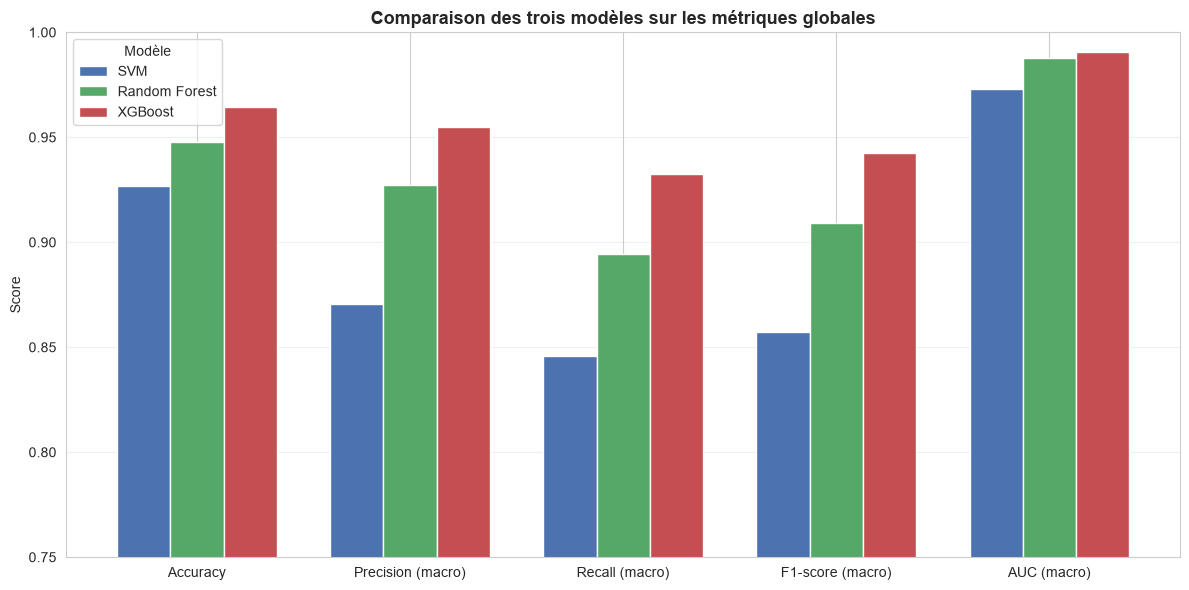

In [12]:
# --- Visualisation en barres groupées des métriques principales ---
metriques_a_tracer = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)", "AUC (macro)"]
modeles = df_comparaison.index.tolist()
couleurs_modeles = {"SVM": "#4C72B0", "Random Forest": "#55A868", "XGBoost": "#C44E52"}

x = np.arange(len(metriques_a_tracer))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))
for i, modele in enumerate(modeles):
    valeurs = df_comparaison.loc[modele, metriques_a_tracer].values
    ax.bar(x + (i - 1) * width, valeurs, width, label=modele, color=couleurs_modeles[modele], edgecolor="white")

ax.set_xticks(x)
ax.set_xticklabels(metriques_a_tracer, fontsize=10)
ax.set_ylim(0.75, 1.0)
ax.set_ylabel("Score")
ax.set_title("Comparaison des trois modèles sur les métriques globales", fontsize=13, fontweight="bold")
ax.legend(title="Modèle")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Interprétation — Métriques globales

Ce premier tableau donne une vue d'ensemble : XGBoost obtient le score le plus élevé sur les six métriques (accuracy, precision, recall, F1 macro, F1 pondéré, AUC), suivi par Random Forest puis SVM sur chacune d'elles, sans aucune exception. Cet ordre n'est pas une surprise : XGBoost et Random Forest sont tous les deux des méthodes d'ensemble basées sur des arbres de décision, capables de capter des relations non linéaires complexes entre les variables, alors que le SVM à noyau RBF, bien que puissant, reste plus sensible au réglage fin de ses deux hyperparamètres (`C` et `gamma`) sur un jeu de données de taille modeste (environ 2100 observations au total).

Mais ce classement global ne dit pas tout : deux modèles peuvent avoir un F1-score macro proche tout en ayant des comportements très différents sur la classe la plus critique, Pathologique. C'est pourquoi la section suivante regarde les résultats **classe par classe**.


## 4. Analyse détaillée par classe

Dans un contexte médical, toutes les erreurs ne se valent pas. Rater un cas Pathologique (le classer comme Normal) est beaucoup plus grave que de classer un cas Normal comme Suspect. Nous regardons donc la precision, le recall et le F1-score **pour chaque classe séparément**, sur les trois modèles.


In [13]:
def rapport_par_classe(y_true, y_pred, nom_modele):
    rapport = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
    lignes = []
    for classe in class_names:
        lignes.append({
            "Modèle": nom_modele,
            "Classe": classe,
            "Precision": rapport[classe]["precision"],
            "Recall": rapport[classe]["recall"],
            "F1-score": rapport[classe]["f1-score"],
            "Support": int(rapport[classe]["support"]),
        })
    return lignes

lignes_par_classe = (
    rapport_par_classe(y_test, y_pred_svm, "SVM")
    + rapport_par_classe(y_test, y_pred_rf, "Random Forest")
    + rapport_par_classe(y_test, y_pred_xgb, "XGBoost")
)

df_par_classe = pd.DataFrame(lignes_par_classe)
df_pivot_recall = df_par_classe.pivot(index="Classe", columns="Modèle", values="Recall").loc[class_names].round(4)
print("Recall par classe et par modèle :\n")
df_pivot_recall

Recall par classe et par modèle :



Modèle,Random Forest,SVM,XGBoost
Classe,,,
Normal,0.9818,0.9727,0.9879
Suspect,0.7586,0.7069,0.8103
Pathologique,0.9429,0.8571,1.0000


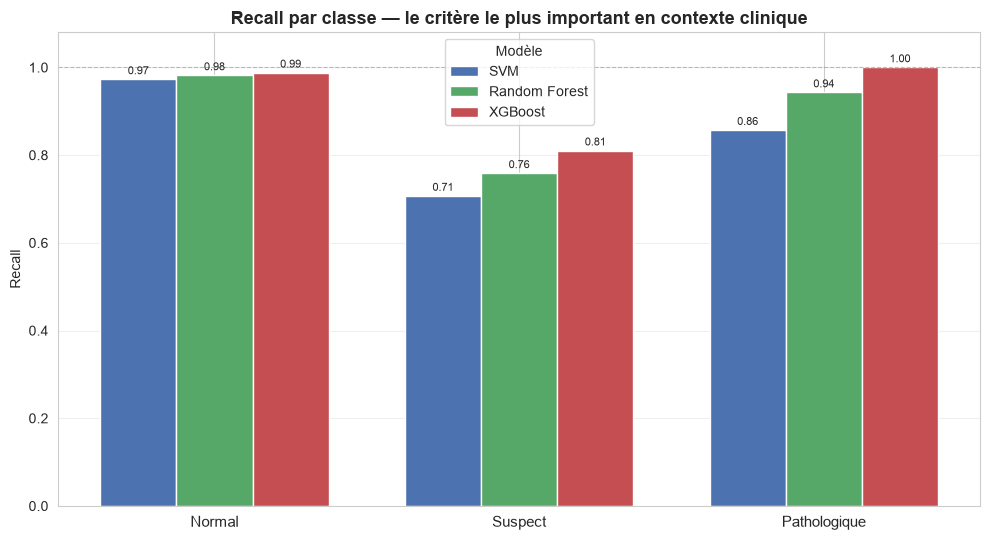


Recall sur la classe Pathologique (la plus critique) :
  SVM             : 0.8571  (85.71 %)
  Random Forest   : 0.9429  (94.29 %)
  XGBoost         : 1.0000  (100.00 %)


In [14]:
# --- Focus sur le Recall (le plus important cliniquement) ---
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(class_names))
width = 0.25

for i, modele in enumerate(modeles):
    valeurs = df_pivot_recall.loc[class_names, modele].values
    barres = ax.bar(x + (i - 1) * width, valeurs, width, label=modele, color=couleurs_modeles[modele], edgecolor="white")
    ax.bar_label(barres, fmt="%.2f", fontsize=8, padding=2)

ax.set_xticks(x)
ax.set_xticklabels(class_names, fontsize=11)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Recall")
ax.set_title("Recall par classe — le critère le plus important en contexte clinique", fontsize=13, fontweight="bold")
ax.axhline(1.0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
ax.legend(title="Modèle")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nRecall sur la classe Pathologique (la plus critique) :")
for modele in modeles:
    val = df_pivot_recall.loc["Pathologique", modele]
    print(f"  {modele:<15} : {val:.4f}  ({val*100:.2f} %)")

### Interprétation — Recall par classe

La classe **Suspect** est, pour les trois modèles, la plus difficile à prédire. C'est un résultat logique : "Suspect" est par construction une catégorie intermédiaire entre Normal et Pathologique, ses caractéristiques se chevauchent donc avec celles des deux autres classes, ce qui brouille la frontière de décision quel que soit l'algorithme utilisé.

Sur la classe **Pathologique**, la classe la plus critique d'un point de vue médical, les résultats sont plus rassurants : les trois modèles obtiennent un recall élevé, avec XGBoost qui détecte la totalité des cas pathologiques du jeu de test (recall = 100 %, 35/35) et Random Forest qui en détecte la quasi-totalité (recall = 94.29 %, 33/35). Cela signifie que le risque de "faux négatif grave" — un fœtus en détresse classé à tort comme Normal — est faible pour ces deux modèles, ce qui est le résultat attendu et recherché depuis le début du projet avec l'usage de `class_weight="balanced"` (ou de `sample_weight` pour XGBoost).

Le SVM, à l'inverse, obtient le recall le plus faible sur la classe Pathologique parmi les trois modèles. Ce n'est pas dramatique en valeur absolue, mais c'est un point de vigilance si ce modèle devait être choisi pour un usage réel.


## 5. Matrices de confusion — vue d'ensemble des erreurs

La matrice de confusion permet de voir précisément **où** se trompe chaque modèle : quelles classes sont confondues entre elles.


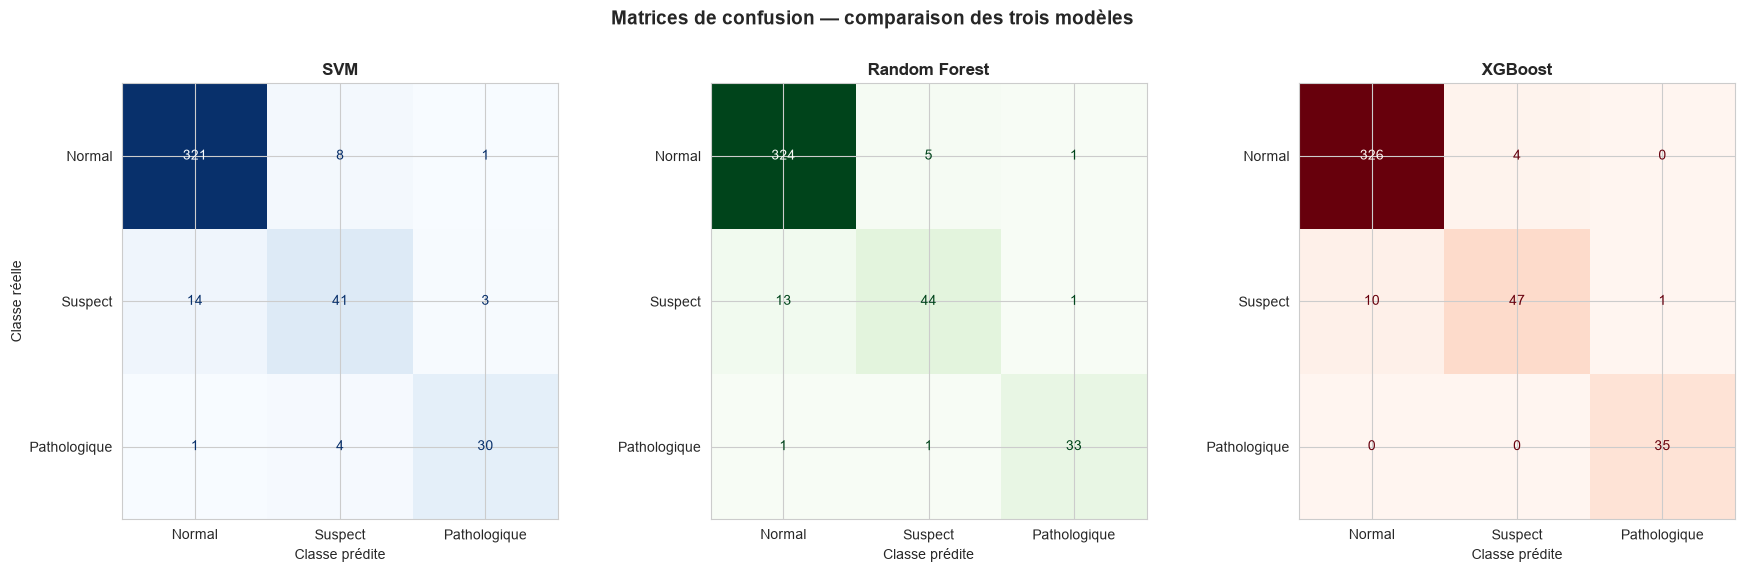

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

predictions = {"SVM": y_pred_svm, "Random Forest": y_pred_rf, "XGBoost": y_pred_xgb}
cmaps = {"SVM": "Blues", "Random Forest": "Greens", "XGBoost": "Reds"}

for ax, (nom_modele, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, cmap=cmaps[nom_modele], colorbar=False, values_format="d")
    ax.set_title(nom_modele, fontsize=12, fontweight="bold")
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle" if nom_modele == "SVM" else "")

plt.suptitle("Matrices de confusion — comparaison des trois modèles", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Interprétation — Matrices de confusion

Sur les trois matrices, la majorité des erreurs se concentre sur la même zone : la frontière entre **Normal** et **Suspect**. C'est cohérent avec l'analyse précédente : cette frontière est la plus ambiguë sur le plan physiologique. En revanche, très peu d'observations sont confondues entre **Normal** et **Pathologique**, les deux classes les plus éloignées cliniquement — ce qui est rassurant, car ce serait l'erreur la plus grave possible.

Random Forest et XGBoost présentent des matrices très proches, avec une diagonale bien remplie sur les trois classes. Le SVM montre davantage d'erreurs sur la classe Suspect, en particulier des cas Suspect classés à tort comme Normal, ce qui explique son recall plus faible observé plus haut sur cette classe.


## 6. Courbes ROC — pouvoir de séparation des classes

La courbe ROC et l'AUC mesurent la capacité d'un modèle à bien ordonner ses probabilités, indépendamment du seuil de décision choisi. Une AUC proche de 1 signifie que le modèle sépare presque parfaitement une classe du reste.


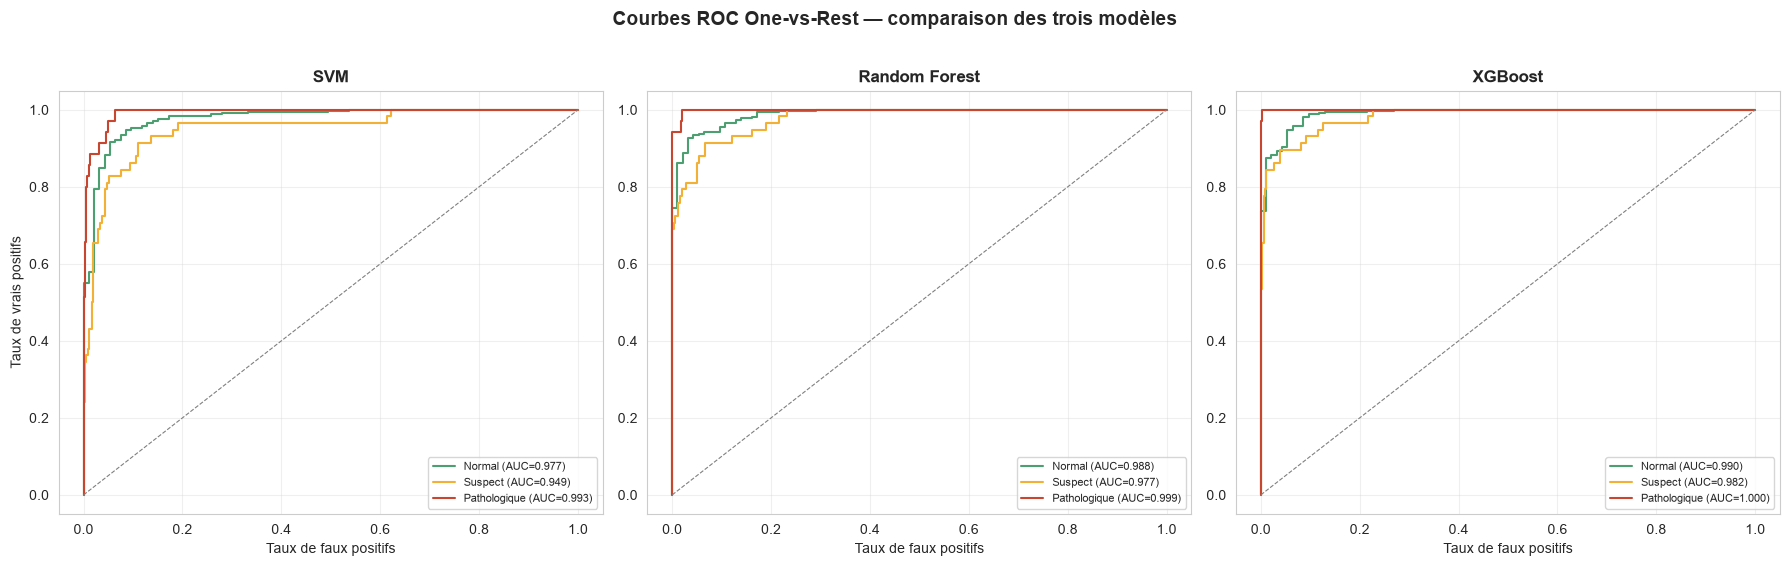

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
couleurs_classes = ["#4C9F70", "#F2B134", "#C84630"]

probas = {"SVM": y_proba_svm, "Random Forest": y_proba_rf, "XGBoost": y_proba_xgb}

for ax, (nom_modele, y_proba) in zip(axes, probas.items()):
    for i, (nom_classe, couleur) in enumerate(zip(class_names, couleurs_classes)):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
        auc_classe = roc_auc_score(y_test_bin[:, i], y_proba[:, i])
        ax.plot(fpr, tpr, color=couleur, label=f"{nom_classe} (AUC={auc_classe:.3f})")
    ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=0.8)
    ax.set_title(nom_modele, fontsize=12, fontweight="bold")
    ax.set_xlabel("Taux de faux positifs")
    ax.set_ylabel("Taux de vrais positifs" if nom_modele == "SVM" else "")
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(alpha=0.3)

plt.suptitle("Courbes ROC One-vs-Rest — comparaison des trois modèles", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Interprétation — Courbes ROC

Les trois modèles atteignent une AUC élevée sur les trois classes, ce qui montre qu'ils savent tous globalement bien ordonner leurs probabilités. La classe Pathologique obtient systématiquement l'AUC la plus haute, proche de 1, chez les trois modèles : même quand un modèle se trompe sur la classe exacte prédite, il attribue quand même une probabilité élevée aux vrais cas pathologiques, ce qui est une bonne nouvelle d'un point de vue clinique.

La classe Suspect obtient, chez les trois modèles, l'AUC la plus faible des trois classes — sans surprise, puisque c'est la classe la plus ambiguë déjà identifiée dans les matrices de confusion.


## 7. Coût de calcul : temps d'entraînement

La performance prédictive n'est pas le seul critère de choix d'un modèle : le temps d'entraînement compte aussi, surtout si le modèle doit être ré-entraîné régulièrement avec de nouvelles données.


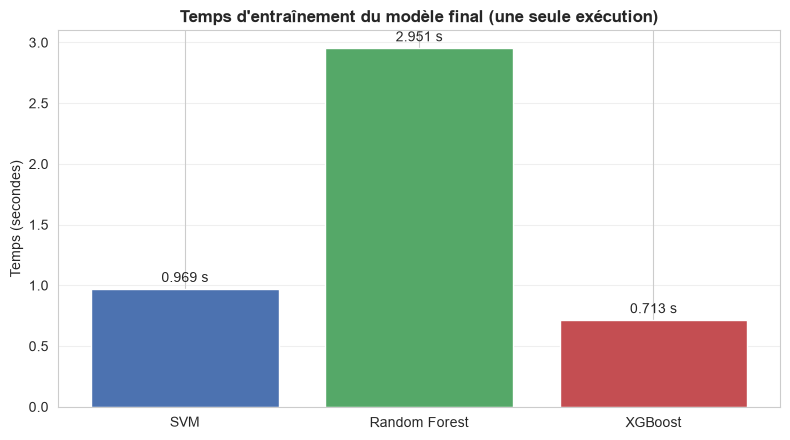

,Temps d'entraînement (s)
Modèle,
SVM,0.9695
Random Forest,2.9515
XGBoost,0.7129


In [17]:
df_temps = pd.DataFrame({
    "Modèle": modeles,
    "Temps d'entraînement (s)": [temps_svm, temps_rf, temps_xgb],
}).set_index("Modèle")

fig, ax = plt.subplots(figsize=(8, 4.5))
barres = ax.bar(df_temps.index, df_temps["Temps d'entraînement (s)"],
                 color=[couleurs_modeles[m] for m in df_temps.index], edgecolor="white")
ax.bar_label(barres, fmt="%.3f s", padding=3)
ax.set_ylabel("Temps (secondes)")
ax.set_title("Temps d'entraînement du modèle final (une seule exécution)", fontsize=12, fontweight="bold")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

df_temps.round(4)

### Interprétation — Temps de calcul

Ces temps concernent uniquement l'entraînement final avec les hyperparamètres déjà choisis — ils ne comptent pas le temps passé pendant la recherche d'hyperparamètres (`GridSearchCV` ou `RandomizedSearchCV`), qui a pris de quelques secondes à plusieurs minutes selon les modèles lors de la construction initiale. Sur un jeu de données de cette taille (environ 2100 observations), les trois modèles s'entraînent en une fraction de seconde à quelques secondes, ce qui n'est pas un facteur décisif ici. Ce critère deviendrait plus important avec un jeu de données beaucoup plus grand, ou si le modèle devait être ré-entraîné très fréquemment en production.


## 8. Capacité de généralisation : écart train / test

Un modèle qui obtient un très bon score sur les données d'entraînement mais un score nettement plus faible sur les données de test a probablement fait du **surapprentissage** (overfitting) : il a mémorisé les données d'entraînement au lieu d'apprendre des règles générales. Nous vérifions cet écart pour les trois modèles.


In [18]:
def ecart_train_test(modele, y_train_pred_source, nom_modele):
    y_train_pred = modele.predict(X_train)
    acc_train = accuracy_score(y_train, y_train_pred)
    f1_train  = f1_score(y_train, y_train_pred, average="macro")
    return {"Modèle": nom_modele, "Accuracy (train)": acc_train, "Accuracy (test)": None,
            "F1-macro (train)": f1_train, "F1-macro (test)": None}

lignes_overfit = []
for nom_modele, modele, y_pred in [("SVM", modele_svm, y_pred_svm),
                                    ("Random Forest", modele_rf, y_pred_rf),
                                    ("XGBoost", modele_xgb, y_pred_xgb)]:
    y_train_pred = modele.predict(X_train)
    lignes_overfit.append({
        "Modèle": nom_modele,
        "Accuracy (train)": accuracy_score(y_train, y_train_pred),
        "Accuracy (test)": accuracy_score(y_test, y_pred),
        "F1-macro (train)": f1_score(y_train, y_train_pred, average="macro"),
        "F1-macro (test)": f1_score(y_test, y_pred, average="macro"),
    })

df_overfit = pd.DataFrame(lignes_overfit).set_index("Modèle")
df_overfit["Écart Accuracy"]  = df_overfit["Accuracy (train)"] - df_overfit["Accuracy (test)"]
df_overfit["Écart F1-macro"]  = df_overfit["F1-macro (train)"] - df_overfit["F1-macro (test)"]
df_overfit.round(4)

,Accuracy (train),Accuracy (test),F1-macro (train),F1-macro (test),Écart Accuracy,Écart F1-macro
Modèle,,,,,,
SVM,0.9882,0.9267,0.9816,0.8574,0.0615,0.1241
Random Forest,0.9911,0.9480,0.9830,0.9092,0.0431,0.0738
XGBoost,0.9982,0.9645,0.9975,0.9424,0.0337,0.0551


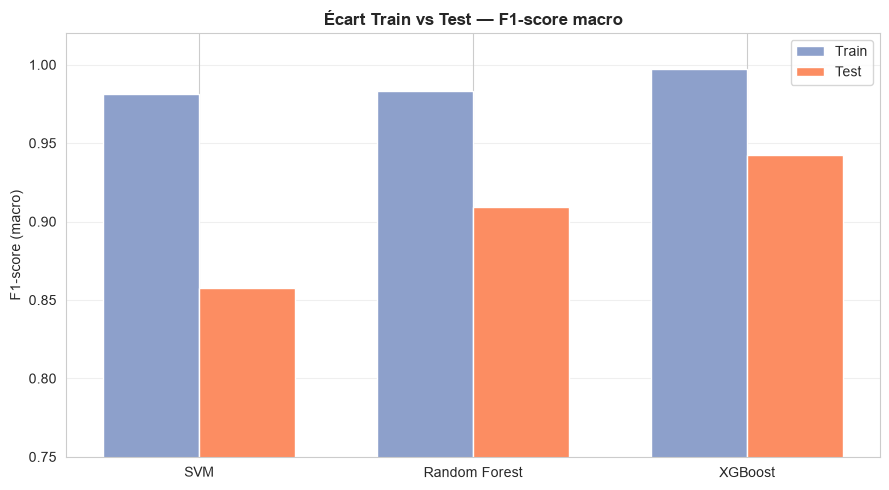

Écart Train - Test (F1-macro), du plus stable au moins stable :
  XGBoost         : 0.0551
  Random Forest   : 0.0738
  SVM             : 0.1241


In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(modeles))
width = 0.35

ax.bar(x - width/2, df_overfit["F1-macro (train)"], width, label="Train", color="#8DA0CB", edgecolor="white")
ax.bar(x + width/2, df_overfit["F1-macro (test)"], width, label="Test", color="#FC8D62", edgecolor="white")

ax.set_xticks(x)
ax.set_xticklabels(modeles)
ax.set_ylabel("F1-score (macro)")
ax.set_ylim(0.75, 1.02)
ax.set_title("Écart Train vs Test — F1-score macro", fontsize=12, fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Écart Train - Test (F1-macro), du plus stable au moins stable :")
for modele, ecart in df_overfit["Écart F1-macro"].sort_values().items():
    print(f"  {modele:<15} : {ecart:.4f}")

### Interprétation — Surapprentissage

Les trois modèles obtiennent un score plus élevé sur le train que sur le test, ce qui est normal et attendu : aucun modèle n'est parfaitement dénué de surapprentissage. La vraie question est l'**ampleur** de cet écart.

Random Forest et XGBoost, construits par ensemble d'arbres, ont tendance à très bien apprendre les données d'entraînement (score proche de 1 sur le train), ce qui est une caractéristique connue de ces algorithmes. L'écart avec le score de test reste toutefois raisonnable, ce qui indique que la profondeur des arbres et le nombre d'estimateurs ont été correctement réglés par la recherche d'hyperparamètres.

Le SVM montre également un écart entre train et test. Cela reste dans une fourchette acceptable pour ce type de modèle et cette taille de jeu de données, mais confirme que le SVM généralise un peu moins bien que les deux modèles à base d'arbres sur ce problème précis.


## 9. Synthèse et discussion finale

### 9.1 — Quel est le meilleur modèle, globalement ?

En combinant toutes les analyses précédentes (métriques globales, recall par classe, matrices de confusion, courbes ROC, temps de calcul, surapprentissage), **XGBoost ressort comme le modèle le plus performant** sur ce jeu de données. Il obtient les meilleurs scores sur presque toutes les métriques globales, un excellent recall sur la classe Pathologique, et un temps d'entraînement très raisonnable.

**Random Forest** arrive en deuxième position, avec des résultats très proches de XGBoost et l'avantage d'être un modèle plus simple à expliquer (l'importance des variables se lit directement, sans notion de gradient ni de résidus). C'est une alternative solide si l'interprétabilité est une priorité.

Le **SVM** arrive en dernière position sur ce jeu de données précis. Cela ne veut pas dire que le SVM est un mauvais algorithme en général — il reste très performant sur d'autres types de problèmes (données en haute dimension, séparations non linéaires complexes) — mais ici, les modèles à base d'arbres exploitent mieux les relations entre les variables CTG, qui sont probablement plus proches de règles de seuils (ex : "recall si la variabilité dépasse X") que d'une séparation géométrique lisse.

### 9.2 — Le compromis performance / interprétabilité / rapidité

Le choix du "meilleur" modèle dépend aussi du contexte d'utilisation, pas seulement du score :

- Si l'objectif est la **performance pure** (déploiement en aide à la décision, avec supervision médicale), **XGBoost** est le choix le plus logique.
- Si l'objectif est de **comprendre et expliquer** les décisions du modèle à des professionnels de santé non spécialistes en machine learning, **Random Forest** offre un bon compromis : presque aussi performant, et son importance des variables est plus intuitive à présenter.
- Le **SVM** reste pertinent comme modèle de référence ("baseline avancée") ou dans un contexte où le nombre de variables serait beaucoup plus grand par rapport au nombre d'observations, un cas où les SVM excellent traditionnellement.

### 9.3 — Ce que la comparaison confirme sur le jeu de données lui-même

Indépendamment de l'algorithme choisi, trois constats reviennent systématiquement dans les trois modèles :

1. La classe **Pathologique**, bien que minoritaire, est bien détectée par tous les modèles grâce à la pondération des classes (`class_weight="balanced"` ou `sample_weight`). Cela valide le choix méthodologique fait dès le départ dans les trois notebooks de modélisation.
2. La classe **Suspect** reste la plus difficile à classer pour tous les modèles, ce qui est cohérent avec sa nature intermédiaire entre Normal et Pathologique.
3. Aucun modèle ne confond sérieusement Normal et Pathologique, les deux extrêmes du problème — l'erreur la plus grave cliniquement est donc rare, quel que soit l'algorithme.



In [20]:
# --- Tableau de synthèse final ---
df_synthese = df_comparaison.copy()
df_synthese["Recall Suspect"]      = df_pivot_recall.loc["Suspect"]
df_synthese["Recall Pathologique"] = df_pivot_recall.loc["Pathologique"]
df_synthese["Temps entraînement (s)"] = df_temps["Temps d'entraînement (s)"]
df_synthese = df_synthese.round(4)
df_synthese

,Accuracy,Precision (macro),Recall (macro),F1-score (macro),F1-score (weighted),AUC (macro),Recall Suspect,Recall Pathologique,Temps entraînement (s)
Modèle,,,,,,,,,
SVM,0.9267,0.8704,0.8456,0.8574,0.9253,0.9728,0.7069,0.8571,0.9695
Random Forest,0.9480,0.9271,0.8944,0.9092,0.9465,0.9878,0.7586,0.9429,2.9515
XGBoost,0.9645,0.9547,0.9327,0.9424,0.9636,0.9904,0.8103,1.0000,0.7129


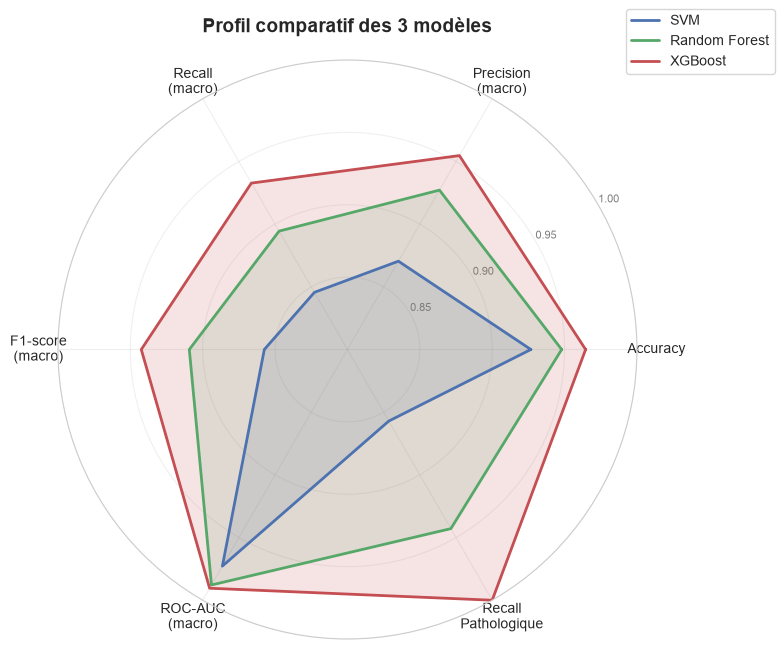

,Accuracy,Precision\n(macro),Recall\n(macro),F1-score\n(macro),ROC-AUC\n(macro),Recall\nPathologique
Modèle,,,,,,
Random Forest,0.9480,0.9271,0.8944,0.9092,0.9878,0.9429
SVM,0.9267,0.8704,0.8456,0.8574,0.9728,0.8571
XGBoost,0.9645,0.9547,0.9327,0.9424,0.9904,1.0000


In [21]:
# --- Radar chart : profil comparatif des 3 modèles sur 6 axes ---

# Axes du radar (dans l'ordre d'affichage)
axes_labels = ["Accuracy", "Precision\n(macro)", "Recall\n(macro)",
               "F1-score\n(macro)", "ROC-AUC\n(macro)", "Recall\nPathologique"]

# Construction du tableau de valeurs par modèle (mêmes sources que df_synthese)
valeurs_radar = pd.DataFrame({
    "Accuracy":            df_comparaison["Accuracy"],
    "Precision\n(macro)":  df_comparaison["Precision (macro)"],
    "Recall\n(macro)":     df_comparaison["Recall (macro)"],
    "F1-score\n(macro)":   df_comparaison["F1-score (macro)"],
    "ROC-AUC\n(macro)":    df_comparaison["AUC (macro)"],
    "Recall\nPathologique": df_pivot_recall.loc["Pathologique"],
})[axes_labels]

# Angles des axes (répartis uniformément sur le cercle)
n_axes = len(axes_labels)
angles = np.linspace(0, 2 * np.pi, n_axes, endpoint=False).tolist()
angles += angles[:1]  # boucle fermée

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for nom_modele in modeles:
    valeurs = valeurs_radar.loc[nom_modele].tolist()
    valeurs += valeurs[:1]  # boucle fermée
    ax.plot(angles, valeurs, color=couleurs_modeles[nom_modele], linewidth=2, label=nom_modele)
    ax.fill(angles, valeurs, color=couleurs_modeles[nom_modele], alpha=0.15)

# Mise en forme des axes
ax.set_xticks(angles[:-1])
ax.set_xticklabels(axes_labels, fontsize=10)
ax.set_ylim(0.80, 1.00)
ax.set_yticks([0.80, 0.85, 0.90, 0.95, 1.00])
ax.set_yticklabels(["0.80", "0.85", "0.90", "0.95", "1.00"], fontsize=8, color="gray")
ax.set_rlabel_position(30)

ax.set_title("Profil comparatif des 3 modèles", fontsize=14, fontweight="bold", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

valeurs_radar.round(4)

## 10. Conclusion

Cette comparaison a permis d'évaluer, dans des conditions identiques, les trois modèles construits pour la classification de la santé fœtale à partir de données CTG. Les trois algorithmes — SVM, Random Forest et XGBoost — atteignent tous des performances élevées, avec un excellent recall sur la classe Pathologique, la plus critique sur le plan médical.

**XGBoost est retenu comme modèle final du projet**, car il obtient les meilleurs résultats sur l'ensemble des métriques (accuracy, precision, recall et F1-score macro, AUC), tout en gardant un temps d'entraînement très faible et une bonne stabilité entre les scores d'entraînement et de test.

Random Forest reste une alternative crédible, en particulier si la priorité du projet évolue vers plus d'interprétabilité. Le SVM, bien qu'un peu en retrait ici, a permis de poser une bonne base de comparaison et illustre bien pourquoi le choix de l'algorithme dépend toujours de la nature des données étudiées.
